# Bước 2: Data Collection, Understanding & Preparation
## Kiểm Toán Chất Lượng Dữ Liệu Theo Khung DAMA-DMBOK & Lưu Vết (Audit Trail)
### Phân Tích Hành Vi Mua Hàng Của Khách Hàng Trong Thương Mại Điện Tử (Tập Dữ Liệu Gốc: 500.000 Bản Ghi)
#### Đề án Môn học: Applied Data Analytics (ADY201m) — ĐH FPT
---


## 2.0 Tuyên ngôn Các Nguyên tắc Quản trị Dữ liệu (Data Governance Principles)

Nhằm đảm bảo tính khoa học, minh bạch và khả năng tái lập trong thực tế doanh nghiệp, toàn bộ quy trình tiền xử lý dữ liệu của dự án được xây dựng dựa trên 3 trụ cột cốt lõi:

1. **Khung Đánh Giá Toàn Diện (DAMA-DMBOK 6 Chiều):**
   Đánh giá và kiểm toán chất lượng dữ liệu có hệ thống theo 6 chiều chuẩn mực quốc tế:
   - *Completeness (Đầy đủ):* Không chứa ô trống (Null/NaN) trên toàn bộ 500.000 bản ghi.
   - *Uniqueness (Duy nhất):* Khử trùng lặp (Deduplication), đảm bảo mỗi bản ghi là một phiên tương tác độc nhất.
   - *Validity (Hợp lệ):* Giá trị biến số phải nằm đúng miền logic thực tế (không chấp nhận số âm ở biến đếm hoặc biến thời gian).
   - *Consistency (Nhất quán):* Logic nghiệp vụ giữa các thuộc tính không mâu thuẫn (ví dụ: ngày mua gần nhất không thể lớn hơn thâm niên tài khoản).
   - *Accuracy (Chính xác):* Giữ nguyên độ chính xác số học (Round-trip precision), không làm tròn sai lệch kiểu số.
   - *Timeliness (Kịp thời):* Phản ánh đúng thời điểm phát sinh hành vi, kiểm soát chặt chẽ mốc thời gian để loại bỏ hoàn toàn rủi ro rò rỉ dữ liệu (No Data Leakage).

2. **Kỹ Thuật Lưu Vết Kiểm Toán (Audit Trail & Reproducibility):**
   - *Tính bất biến của dữ liệu gốc:* Tuyệt đối không can thiệp hay ghi đè lên file dữ liệu ban đầu. Kiểm định tính toàn vẹn cấu trúc (500.000 dòng × 17 cột) bằng bảng cờ lỗi `issues` độc lập.
   - *Phân tách có lưu vết:* Tách 100% bản ghi vi phạm (67.744 dòng) sang kho lưu trữ riêng (`customerData_rejected.csv`) theo đúng chỉ số dòng gốc, đảm bảo mọi thao tác đều có thể truy vết và kiểm chứng.

3. **Bảo Toàn Tính Đại Diện & Chân Thực Của Thị Trường:**
   - Phân định rạch ròi giữa **dữ liệu sai hỏng kỹ thuật/logic** (7 vấn đề cần bóc tách) và **biến thiên tự nhiên của khách hàng thật** (như nhóm khách hàng có thu nhập cao hoặc gắn bó lâu năm).
   - Dự án bảo toàn trọn vẹn các quan sát thực tế này, không sử dụng công thức toán cắt gọt cơ học (Trimming hay Winsorization theo IQR) làm méo mó chân dung khách hàng thật.

## 2.1 Import Thư viện & Thiết lập Môi trường Làm việc

**Mục tiêu:** Nạp các thư viện phân tích dữ liệu cốt lõi (`pandas`, `numpy`, `os`) và tự động thiết lập đường dẫn truy xuất tệp dữ liệu, đảm bảo code chạy tương thích và ổn định ở mọi môi trường thực thi.


In [28]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Thiết lập đường dẫn dữ liệu tự động (chạy từ thư mục gốc hoặc thư mục Notebooks)
DATA_DIR = next((p for p in [os.path.join('..', 'Data'), 'Data', '.'] if os.path.exists(os.path.join(p, 'customerData_500k.csv'))), '.')
RAW_PATH = os.path.join(DATA_DIR, 'customerData_500k.csv')
CLEAN_PATH = os.path.join(DATA_DIR, 'customerData_clean.csv')
REJECTED_PATH = os.path.join(DATA_DIR, 'customerData_rejected.csv')
assert os.path.exists(RAW_PATH), f'Cảnh báo: Không tìm thấy file {RAW_PATH}!'

## 2.2 Nạp Dữ Liệu & Kiểm Toán Tính Đầy Đủ Chuẩn DAMA-DMBOK

* **Mục tiêu:** Xác thực tính toàn vẹn cấu trúc (500.000 dòng × 17 cột), kiểm tra tính Duy nhất (Uniqueness) và lập bảng kiểm toán tính Đầy đủ (Completeness) cho từng thuộc tính.
* **Nguyên tắc:** Dù dữ liệu không khuyết thiếu, quy trình kiểm toán bắt buộc phải định lượng rõ ràng 0% Missing cho toàn bộ 17 cột để chứng minh không cần dùng kỹ thuật điền khuyết nhân tạo (Imputation).

In [29]:
raw = pd.read_csv(RAW_PATH, float_precision='round_trip')

print(f"Kích thước dữ liệu gốc: {raw.shape[0]:,} dòng × {raw.shape[1]} cột")
print(f"Trùng lặp: {raw.duplicated().sum():,} dòng (0.00%) | Tổng ô khuyết thiếu: {raw.isna().sum().sum():,} ô (0.00%)")

missing_audit = pd.DataFrame({
    'Kiểu dữ liệu': raw.dtypes
})
display(missing_audit)

Kích thước dữ liệu gốc: 500,000 dòng × 17 cột
Trùng lặp: 0 dòng (0.00%) | Tổng ô khuyết thiếu: 0 ô (0.00%)


,Kiểu dữ liệu
Age,int64
AnnualIncome,float64
NumberOfPurchases,int64
TimeSpentOnWebsite,float64
CustomerTenureYears,float64
LastPurchaseDaysAgo,int64
Gender,str
ProductCategory,str
PreferredDevice,str
Region,str


## 2.2.1 Thăm Dò Phân Phối Bằng Boxplot & Đánh Giá Giới Hạn Của Phương Pháp IQR

* **Mục tiêu:** Thăm dò hình dạng phân phối của 6 biến số định lượng quan trọng và kiểm tra tính khả thi của phương pháp phát hiện ngoại lai truyền thống theo chuẩn $1.5 \times \text{IQR}$.
* **Công thức thống kê:** Ngưỡng dưới = $Q1 - 1.5 \times \text{IQR}$; Ngưỡng trên = $Q3 + 1.5 \times \text{IQR}$.

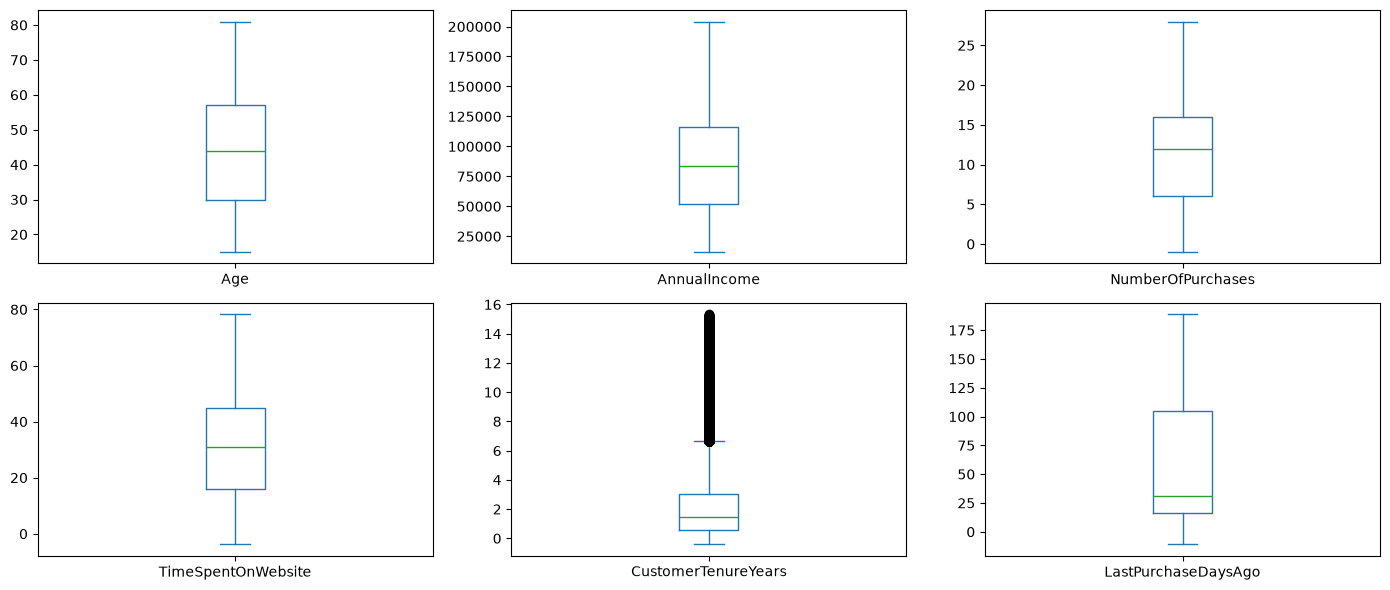

,Ngưỡng dưới,Ngưỡng trên,Số dòng ngoài ngưỡng,Tỷ lệ (%)
Age,-10.50,97.50,0,0.0%
AnnualIncome,-44835.00,213388.51,0,0.0%
NumberOfPurchases,-9.00,31.00,0,0.0%
TimeSpentOnWebsite,-27.91,88.77,0,0.0%
CustomerTenureYears,-3.03,6.64,24803,4.96%
LastPurchaseDaysAgo,-117.50,238.50,0,0.0%


In [30]:
import matplotlib.pyplot as plt

cols = ['Age', 'AnnualIncome', 'NumberOfPurchases', 'TimeSpentOnWebsite', 'CustomerTenureYears', 'LastPurchaseDaysAgo']
fig, axes = plt.subplots(2, 3, figsize=(14, 6))
raw[cols].plot(kind='box', subplots=True, ax=axes)
plt.tight_layout()
plt.show()

q1, q3 = raw[cols].quantile(0.25), raw[cols].quantile(0.75)
lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
outliers = (raw[cols] < lower) | (raw[cols] > upper)

display(pd.DataFrame({
    'Ngưỡng dưới': lower.round(2),
    'Ngưỡng trên': upper.round(2),
    'Số dòng ngoài ngưỡng': outliers.sum(),
    'Tỷ lệ (%)': (outliers.mean() * 100).round(2).astype(str) + '%'
}))

> **Kết luận kiểm toán: Cơ sở khoa học bác bỏ phương pháp lọc theo IQR thuần túy**
>
> Bảng tính toán định lượng trên chứng minh phương pháp $1.5 \times \text{IQR}$ bộc lộ **2 hạn chế nghiêm trọng** khi áp dụng vào dữ liệu thương mại điện tử:
> 1. **Bỏ lọt lỗi hệ thống (False Negative):** Do dữ liệu phân phối trải rộng, ngưỡng dưới của hầu hết các biến đều bị âm sâu ($-9.0$ lần mua, $-27.91$ phút, $-117.5$ ngày). Phương pháp IQR hoàn toàn **bỏ sót toàn bộ các bản ghi lỗi hệ thống có giá trị âm** (`-1` lần mua, thời gian âm do lệch clock log) vì coi các giá trị này vẫn "nằm trong ngưỡng hợp lệ".
> 2. **Triệt tiêu tệp khách hàng giá trị cao (False Positive):** Ở biến thâm niên `CustomerTenureYears`, ngưỡng trên là $6.64$ năm. Nếu máy móc cắt bỏ (Trimming) hay ép trần (Capping), hệ thống sẽ **loại bỏ oan 24.803 khách hàng trung thành nhất** (chiếm 4.96% toàn sàn) — vốn là tệp người dùng mang lại giá trị vòng đời (LTV) cao nhất cho doanh nghiệp.
>
> 👉 **KẾT LUẬN & ĐỊNH HƯỚNG:** Phương pháp thống kê IQR thuần túy không phản ánh đúng bản chất hành vi tiêu dùng và không phát hiện được mâu thuẫn đa biến. Đây là cơ sở thực nghiệm vững chắc để dự án xây dựng **Khung 7 vấn đề kiểm toán logic nghiệp vụ (Audit Trail)** tại Mục 2.3 dưới đây.

## 2.3 Thiết Lập Bảng Lưu Vết Kiểm Toán (Audit Trail) Cho 7 Vấn Đề Nghiệp Vụ

Tuân thủ nguyên tắc quản trị dữ liệu, quy trình làm sạch **không xóa trực tiếp dữ liệu thô** mà sử dụng cơ chế **Lưu vết kiểm toán (Audit Trail)**. Bảng `issues` được khởi tạo song song với 500.000 bản ghi gốc để ghi nhận độc lập các cờ vi phạm (flags) qua 7 quy tắc nghiệp vụ, giúp việc phân tách dữ liệu minh bạch và truy xuất được nguồn gốc lỗi.

In [31]:
# Khởi tạo bảng lưu vết kiểm toán lỗi cho 500.000 bản ghi gốc
issues = pd.DataFrame(index=raw.index)

### 2.3.1 Vấn đề 1: Sai miền giá trị (Số âm đơn biến)

* **Thực tế dữ liệu:** 4 biến định lượng gồm số lần mua (`NumberOfPurchases`) và các biến thời gian (`TimeSpentOnWebsite`, `CustomerTenureYears`, `LastPurchaseDaysAgo`) ghi nhận **27.435 bản ghi mang giá trị âm (chiếm 5,49%)**. Số lần mua nhỏ nhất bị ghi nhận là `-1` (mã lỗi kỹ thuật của hệ thống thanh toán), còn thời gian âm phát sinh do lệch đồng hồ khi đồng bộ log.
* **Rủi ro & Tác động lên phân tích:**
  - *Nếu để nguyên:* Giá trị âm ở `LastPurchaseDaysAgo` sẽ làm sai lệch hoàn toàn điểm số Recency trong ma trận RFM (Notebook 4); đồng thời khiến mô hình Machine Learning (Notebook 6) học sai phân phối của các biến đếm (vốn bắt buộc phải là số nguyên không âm).
  - *Nếu xử lý sai bằng `abs()` để đổi dấu:* Sẽ biến hơn 27.000 lỗi hệ thống thành "khách hàng thật đã mua 1 lần", trực tiếp thổi phồng tỷ lệ chuyển đổi ảo của toàn sàn.
* **Giải pháp xử lý:** Không điền số trung bình để tránh làm méo mó phân phối. Giải pháp an toàn nhất là bóc tách toàn bộ **27.435 dòng này (5,49%)** sang tệp `customerData_rejected.csv` để đội ngũ kỹ thuật rà soát lỗi log.

In [32]:
# Vấn đề 1: Đánh dấu các bản ghi có giá trị âm ở 4 biến định lượng
issues['neg_values'] = (
    (raw['NumberOfPurchases'] < 0) |
    (raw['TimeSpentOnWebsite'] < 0) |
    (raw['CustomerTenureYears'] < 0) |
    (raw['LastPurchaseDaysAgo'] < 0)
)

### 2.3.2 Vấn đề 2: Nghịch lý thời gian — Mua hàng trước khi tạo tài khoản

* **Thực tế dữ liệu:** Điều kiện `LastPurchaseDaysAgo > CustomerTenureYears * 365.25` phát hiện **40.666 bản ghi vi phạm (chiếm 8,13%)**. 100% các dòng này rơi vào tài khoản mới mở (< 6 tháng), điển hình có khách tạo nick 6 ngày nhưng hệ thống ghi nhận phát sinh 18 đơn mua từ 181 ngày trước. Lỗi phát sinh do gộp lịch sử mua của khách vãng lai hoặc reset mốc thời gian khi chuyển đổi hệ thống.
* **Rủi ro & Tác động lên phân tích:**
  - *Nếu để nguyên:* Làm sai lệch trực tiếp biến Recency khiến ma trận RFM và biểu đồ Heatmap (Notebook 4 & 5) bị biến dạng; đồng thời khách mới bị đội lốt khách mua nhiều đơn, làm sai lệch kết quả truy vấn SQL và khiến mô hình Machine Learning (Notebook 6) học sai quy luật hành vi theo thời gian.
  - *Nếu xử lý sai (tự ý lùi ngày tạo nick hoặc reset ngày mua):* Sẽ tạo ra thâm niên ảo, làm sai lệch phân tích đoàn hệ khách hàng (Cohort Analysis).
* **Giải pháp xử lý:** Không tự ý sửa mốc thời gian. Biện pháp chuẩn mực là bóc tách toàn bộ **40.666 dòng này (chiếm 8,13%)** sang tệp `customerData_rejected.csv` để bảo toàn tính nhất quán thời gian.

In [33]:
# Vấn đề 2: Mua hàng trước ngày tạo tài khoản
issues['purchase_before_tenure'] = raw['LastPurchaseDaysAgo'] > (raw['CustomerTenureYears'] * 365.25)

### 2.3.3 Vấn đề 3: Mâu thuẫn giao dịch — Chưa mua hàng nhưng có ngày mua gần nhất

* **Thực tế dữ liệu:** Điều kiện `NumberOfPurchases == 0` nhưng `LastPurchaseDaysAgo > 0` phát hiện **8.125 bản ghi mâu thuẫn (chiếm 1,63%)**. Khi ghép với biến mục tiêu `PurchaseStatus`, dữ liệu bộc lộ 2 nghịch lý cụ thể:
  - *Khi khách chốt đơn trong phiên (`PurchaseStatus = 1` — 2.749 dòng):* Vì lịch sử ghi `NumberOfPurchases = 0` (chưa từng mua gì), nên đơn hàng khách bấm mua hôm nay chính là đơn hàng đầu tiên trong đời. Thế nhưng cột `LastPurchaseDaysAgo` lại ghi nhận khách đã có lần mua cách đây 61 ngày (`> 0`). Nghịch lý là một người đang mua đơn hàng đầu tiên thì không thể có "ngày mua gần nhất từ 2 tháng trước".
  - *Khi khách không mua trong phiên (`PurchaseStatus = 0` — 5.376 dòng):* Quá khứ chưa từng mua (`NumberOfPurchases = 0`), phiên này cũng không mua (`PurchaseStatus = 0`), nghĩa là tài khoản này chưa bao giờ phát sinh bất kỳ đơn hàng nào. Vậy con số `LastPurchaseDaysAgo > 0` từ đâu ra? Một người chưa từng mua hàng thì mốc thời gian "cách lần mua gần nhất bao nhiêu ngày" là hoàn toàn vô căn cứ.
* **Rủi ro & Tác động lên phân tích:**
  - *Bối cảnh hồ sơ bất thường:* Kiểm tra sâu cho thấy nhóm này đã mở tài khoản trung bình hơn 2 năm, đã áp dụng trung bình 3 mã giảm giá, và có tới **77% được gắn mác VIP/Premium**.
  - *Hậu quả nếu để nguyên:* Sự mâu thuẫn này làm mô hình học máy (Notebook 6) bị nhiễu loạn nghiêm trọng: thuật toán không thể phân biệt được đâu là đặc trưng chốt đơn của **khách mới mua lần đầu** và đâu là của **khách VIP mua lặp lại**; đồng thời làm sai lệch biến Recency trong phân tích SQL và ma trận RFM (Notebook 3 & 4).
  - *Nếu xử lý sai (tự gán `NumberOfPurchases = 1` hoặc ép `LastPurchaseDaysAgo = 0`):* Sẽ tự ý bịa thêm đơn hàng lịch sử hoặc xóa mất dấu vết tương tác, làm méo mó chân dung phân khúc khách hàng mới.
* **Giải pháp xử lý:** Không thể xác định cột nào ghi nhận đúng để sửa chữa. Biện pháp an toàn và chuẩn mực nhất là bóc tách toàn bộ **8.125 dòng này (chiếm 1,63%)** sang tệp `customerData_rejected.csv`.

In [34]:
# Vấn đề 3: Chưa mua hàng nhưng có ngày mua gần nhất
issues['zero_purchases_has_last_date'] = (raw['NumberOfPurchases'] == 0) & (raw['LastPurchaseDaysAgo'] > 0)

### 2.3.4 Vấn đề 4: Mâu thuẫn khuyến mãi — Chưa mua hàng nhưng đã tiêu dùng mã giảm giá

* **Thực tế dữ liệu:** Điều kiện lọc `NumberOfPurchases == 0` nhưng `DiscountsAvailed > 0` phát hiện **7.534 bản ghi phi lý (chiếm 1,51%)**. Trong thực tế TMĐT, một đơn hàng có thể gộp nhiều mã giảm giá (voucher sàn, voucher shop, freeship). Tuy nhiên, khi bóc tách chi tiết 7.534 dòng này theo trạng thái mua hàng (`PurchaseStatus`) và ngày mua gần nhất (`LastPurchaseDaysAgo`), dữ liệu phân hóa thành 3 nhóm mâu thuẫn rõ rệt:
  - *Nhóm 1 — Hoàn toàn không có đơn hàng nào để áp mã (4.836 dòng — 64,2%):* Khách có `PurchaseStatus = 0` (phiên này không mua) và `NumberOfPurchases = 0` (quá khứ chưa từng mua). Khách hàng không hề phát sinh bất kỳ đơn hàng nào nhưng hệ thống vẫn ghi nhận đã tiêu dùng từ 1 đến 10 voucher vào không khí.
  - *Nhóm 2 — Chốt đơn hôm nay nhưng mâu thuẫn lịch sử mua cũ (2.638 dòng — 35,0%):* Khách có `PurchaseStatus = 1`, nhưng `LastPurchaseDaysAgo` lại ghi nhận lần mua gần nhất từ 60 – 180 ngày trước. Nếu khách đã từng mua và áp mã từ nhiều tháng trước, tại sao bộ đếm `NumberOfPurchases` lại không ghi nhận đơn hàng đó mà vẫn để bằng 0?
  - *Nhóm 3 — Khách mua hôm nay và áp nhiều mã tân thủ (60 dòng — 0,8%):* Nhóm duy nhất thỏa mãn kịch bản mua đơn đầu tiên hôm nay (`PurchaseStatus = 1` và `LastPurchaseDaysAgo = 0`). Tuy nhiên, ngay cả ở 60 dòng này, có tới 80% khách hàng đã mang cấp bậc VIP/Premium với thâm niên trung bình gần 2 năm — một nghịch lý lớn vì không hệ thống nào phong VIP cho tài khoản 2 năm chưa từng phát sinh đơn hàng.
* **Rủi ro & Tác động lên phân tích:**
  - *Nếu để nguyên:* Phá vỡ hoàn toàn câu hỏi nghiên cứu RQ3 (Notebook 1) và các truy vấn SQL đánh giá hiệu quả khuyến mãi (Notebook 3). Dữ liệu mâu thuẫn này làm sai lệch tỷ lệ chuyển đổi thực tế, khiến mô hình Machine Learning (Notebook 6) rút ra kết luận sai lầm: cấp càng nhiều voucher thì khách càng không có đơn hàng.
  - *Nếu xử lý sai (tự ép số voucher về 0 hoặc tự đoán số đơn hàng để bù vào):* Sẽ can thiệp thô bạo vào thuộc tính `DiscountsAvailed`, làm méo mó thước đo độ nhạy cảm về giá của khách hàng.
* **Giải pháp xử lý:** Không thể tự đoán số đơn hàng để sửa và cũng không thể gán số voucher về 0. Biện pháp an toàn nhất là bóc tách toàn bộ **7.534 dòng này (chiếm 1,51%)** sang tệp `customerData_rejected.csv`.

In [35]:
# Vấn đề 4: Chưa mua hàng nhưng có lượt áp dụng mã giảm giá
issues['zero_purchases_used_discounts'] = (raw['NumberOfPurchases'] == 0) & (raw['DiscountsAvailed'] > 0)

### 2.3.5 Vấn đề 5: Mâu thuẫn phân khúc — Chưa từng mua hàng nhưng xếp hạng VIP/Premium

* **Thực tế dữ liệu:** Điều kiện `NumberOfPurchases == 0` nhưng `CustomerSegment` thuộc nhóm `['VIP', 'Premium']` ghi nhận **6.426 bản ghi sai lệch (chiếm 1,29%)**, bao gồm 3.946 khách Premium và 2.480 khách VIP. Trong thực tế nghiệp vụ bán lẻ, phân hạng VIP và Premium bắt buộc phải tích lũy từ lịch sử mua sắm và doanh số chi tiêu thực tế. Một tài khoản chưa từng hoàn tất bất kỳ giao dịch nào không thể được thăng hạng lên phân khúc khách hàng giá trị cao nhất.
* **Rủi ro & Tác động lên phân tích:**
  - *Nếu để nguyên:* Làm méo mó toàn bộ phân tích so sánh giữa các phân khúc khách hàng bằng SQL và trực quan hóa (Notebook 3 & 5) do nhóm VIP/Premium bị "pha loãng" bởi hơn 6.400 tài khoản ảo mang 0 đơn hàng; đồng thời làm đặc trưng `Segment_VIP` trong mô hình Machine Learning (Notebook 6) bị nhiễu loạn tín hiệu, khiến thuật toán học sai hành vi chuyển đổi của nhóm khách hàng cao cấp thực thụ.
  - *Nếu xử lý sai (tự ý giáng hạng khách về `Regular`):* Có thể vô tình xóa mất dấu vết của các tài khoản thử nghiệm kỹ thuật (test accounts) của nội bộ sàn, làm lẫn lộn hành vi bất thường vào tệp khách hàng thông thường.
* **Giải pháp xử lý:** Không thể tự ý đổi hạng. Biện pháp chuẩn mực là bóc tách toàn bộ **6.426 dòng này (chiếm 1,29%)** sang tệp `customerData_rejected.csv` để đảm bảo phân khúc VIP/Premium chỉ đại diện cho khách hàng có giá trị cao thực sự.

In [36]:
# Vấn đề 5: Chưa mua hàng nhưng xếp hạng VIP/Premium
issues['zero_purchases_vip_segment'] = (raw['NumberOfPurchases'] == 0) & (raw['CustomerSegment'].isin(['VIP', 'Premium']))

### 2.3.6 Vấn đề 6: Vi phạm quy định pháp lý — Tuổi tạo tài khoản dưới 13 tuổi (COPPA/GDPR)

* **Thực tế dữ liệu:** Điều kiện `(Age - CustomerTenureYears) < 13` phát hiện **3.925 bản ghi vi phạm (chiếm 0,79%)**. Khi lấy tuổi hiện tại trừ đi thâm niên, độ tuổi lúc mở tài khoản của nhóm này chỉ từ 1,9 đến dưới 13 tuổi (trung bình là 10,9 tuổi). Điển hình có trường hợp khách hàng 18 tuổi nhưng thâm niên 8,5 năm (tức tạo nick độc lập từ lúc 9 tuổi). Đây là lỗi sinh dữ liệu giả lập (synthetic artifact) khi kết hợp ngẫu nhiên độ tuổi thanh thiếu niên với số năm thâm niên quá lớn.
* **Rủi ro & Tác động lên phân tích:**
  - *Nếu để nguyên:* Vi phạm các chuẩn mực pháp lý quốc tế về bảo vệ quyền riêng tư trẻ em trên không gian mạng (Đạo luật COPPA, GDPR và điều khoản sàn TMĐT cấm trẻ dưới 13 tuổi tự mở tài khoản và giao dịch độc lập); đồng thời làm sai lệch câu hỏi nghiên cứu RQ1 (Notebook 1) và phân tích nhóm khách trẻ (`Young < 30`) khi xuất hiện các hồ sơ phi thực tế (trẻ em 9 – 10 tuổi mua sắm với thu nhập hàng chục nghìn USD).
  - *Nếu xử lý sai (tự ý tăng tuổi khách hàng hoặc gọt bớt số năm thâm niên):* Sẽ can thiệp chủ quan vào cấu trúc nhân khẩu học và làm méo mó phân phối độ tuổi thật của mẫu nghiên cứu.
* **Giải pháp xử lý:** Không thể tự ý tăng tuổi hay cắt bớt thâm niên. Biện pháp chuẩn mực là bóc tách toàn bộ **3.925 dòng này (chiếm 0,79%)** sang tệp `customerData_rejected.csv` để đảm bảo mẫu dữ liệu tuân thủ chuẩn mực pháp lý và logic xã hội học.

In [37]:
# Vấn đề 6: Độ tuổi khi tạo tài khoản dưới 13 tuổi
issues['underage_account_creation'] = (raw['Age'] - raw['CustomerTenureYears']) < 13

### 2.3.7 Vấn đề 7: Hành vi nghi vấn Bot / Spam đánh giá cực đoan

* **Thực tế dữ liệu:** Điều kiện `TimeSpentOnWebsite < 1` và `PurchaseStatus == 0` và `CustomerSatisfaction in [1, 5]` phát hiện **601 bản ghi bất thường (chiếm 0,12%)**, bao gồm 447 lượt chấm 5 sao và 154 lượt chấm 1 sao. Khách truy cập web chưa đầy 1 phút (nhiều phiên chỉ vài giây), hoàn toàn không phát sinh giao dịch, nhưng lại lập tức đánh giá trải nghiệm ở hai thái cực cảm xúc tuyệt đối.
* **Rủi ro & Tác động lên phân tích:**
  - *Bản chất hiện tượng phân cực hai đầu (Bimodal Extreme Polarity):* Một người chưa mua món nào, vào web vài chục giây thì không thể có trải nghiệm hoàn hảo để chấm 5 sao (dấu hiệu của Bot seeding tạo uy tín ảo), và cũng chưa thể có trải nghiệm tồi tệ để căm phẫn chấm 1 sao (dấu hiệu của Review Bombing phá hoại hoặc lỗi văng app). Bot chạy kịch bản tự động thường chỉ nhắm vào 2 cực để tâng bốc hoặc dìm hàng tối đa.
  - *Cân nhắc khoa học (Tại sao không lọc điểm 2, 3, 4 sao):* Có hơn 10.000 khách vào dưới 1 phút chấm 2, 3, 4 sao. Đây là hành vi tự nhiên của người thật khi lướt dạo không ưng ý bấm thoát (Bounce Rate) và chọn điểm trung tính/vừa phải để tắt khảo sát. Nếu lọc cả nhóm này sẽ xóa oan khách hàng thật.
  - *Hậu quả nếu để nguyên:* Tạo tín hiệu giả (noise) gây nhiễu loạn biến `CustomerSatisfaction` và làm giảm độ chính xác của các mô hình phân loại (Notebook 6).
* **Giải pháp xử lý:** Bóc tách chuẩn xác **601 dòng này (chiếm 0,12%)** sang tệp `customerData_rejected.csv`, vừa bảo vệ độ sạch cho biến điểm đánh giá trải nghiệm, vừa bảo toàn trọn vẹn tệp khách hàng thật lướt dạo.

In [38]:
# Vấn đề 7: Nghi vấn Bot/Spam đánh giá cực đoan không mua hàng
issues['bot_extreme_review'] = (raw['TimeSpentOnWebsite'] < 1) & (raw['PurchaseStatus'] == 0) & (raw['CustomerSatisfaction'].isin([1, 5]))

## 2.4 Tổng Hợp Bóc Tách Dữ Liệu Sạch (Clean) & Dữ Liệu Từ Chối (Rejected)

Sau khi kiểm toán độc lập qua 7 vấn đề nghiệp vụ, tiến hành hợp nhất toàn bộ các dòng vi phạm (phép toán `OR` logic) để phân tách bộ dữ liệu thành 2 tập riêng biệt:
- **Tập Hợp Lệ (Clean):** Giữ lại các bản ghi nhất quán để phục vụ phân tích mô tả, RFM, SQL và huấn luyện mô hình Machine Learning.
- **Tập Từ Chối (Rejected):** Lưu trữ toàn bộ các bản ghi vi phạm kèm lưu vết kiểm toán (Audit Trail) để đội ngũ kỹ thuật hệ thống rà soát lỗi backend.

In [39]:
rejected_mask = issues.any(axis=1)
clean = raw[~rejected_mask].copy()
rejected = raw[rejected_mask].copy()

summary = issues.sum().rename({
    'neg_values': '1. Sai miền giá trị (Số âm)',
    'purchase_before_tenure': '2. Mua hàng trước khi tạo nick',
    'zero_purchases_has_last_date': '3. Chưa mua nhưng có ngày mua',
    'zero_purchases_used_discounts': '4. Chưa mua nhưng dùng voucher',
    'zero_purchases_vip_segment': '5. Chưa mua nhưng là VIP/Premium',
    'underage_account_creation': '6. Tuổi mở nick < 13 tuổi',
    'bot_extreme_review': '7. Bot/Spam đánh giá cực đoan'
}).to_frame('Số dòng')

summary.loc['TỔNG LỖI (Hợp nhất OR)'] = rejected_mask.sum()
summary.loc['DỮ LIỆU SẠCH (Hợp lệ)'] = len(clean)
summary['Tỷ lệ (%)'] = (summary['Số dòng'] / len(raw) * 100).round(2)
summary

,Số dòng,Tỷ lệ (%)
1. Sai miền giá trị (Số âm),27435,5.49
2. Mua hàng trước khi tạo nick,40666,8.13
3. Chưa mua nhưng có ngày mua,8125,1.62
4. Chưa mua nhưng dùng voucher,7534,1.51
5. Chưa mua nhưng là VIP/Premium,6426,1.29
6. Tuổi mở nick < 13 tuổi,3925,0.78
7. Bot/Spam đánh giá cực đoan,601,0.12
TỔNG LỖI (Hợp nhất OR),67744,13.55
DỮ LIỆU SẠCH (Hợp lệ),432256,86.45


## 2.4.1 Chuẩn Hóa Dữ Liệu Số & Định Dạng Thời Gian Trực Quan (Phút - Giây, Năm - Tháng)

* **Làm tròn tiền tệ & thời gian:** Làm tròn 2 số thập phân cho `AnnualIncome`, `TimeSpentOnWebsite`, `CustomerTenureYears`.
* **Trực quan hóa thời gian:** Bổ sung 2 cột đọc hiểu `TimeSpent_Formatted` (Phút & Giây) và `Tenure_Formatted` (Năm & Tháng) phục vụ hiển thị báo cáo.
* **Bảo toàn tính toán:** Giữ nguyên các trường định lượng gốc dạng số thực để cung cấp cho SQL (Notebook 3) và Machine Learning (Notebook 6).

In [40]:
clean[['AnnualIncome', 'TimeSpentOnWebsite', 'CustomerTenureYears']] = clean[['AnnualIncome', 'TimeSpentOnWebsite', 'CustomerTenureYears']].round(2)

clean['TimeSpent_Formatted'] = clean['TimeSpentOnWebsite'].apply(lambda x: f"{int(x)} phút {int(round((x % 1) * 60)):02d} giây")
clean['Tenure_Formatted'] = clean['CustomerTenureYears'].apply(lambda x: f"{int(x)} năm {int(round((x % 1) * 12))} tháng" if int(x) > 0 else f"{int(round(x * 12))} tháng")

display(clean[['AnnualIncome', 'TimeSpentOnWebsite', 'TimeSpent_Formatted', 'CustomerTenureYears', 'Tenure_Formatted']].head())

,AnnualIncome,TimeSpentOnWebsite,TimeSpent_Formatted,CustomerTenureYears,Tenure_Formatted
0,57722.57,5.91,5 phút 55 giây,1.09,1 năm 1 tháng
1,21328.93,6.97,6 phút 58 giây,0.65,8 tháng
2,150537.74,35.00,35 phút 00 giây,3.86,3 năm 10 tháng
5,25950.81,54.26,54 phút 16 giây,4.91,4 năm 11 tháng
7,51222.01,57.51,57 phút 31 giây,1.01,1 năm 0 tháng


## 2.4.2 Bảng So Sánh Đối Chứng Dữ Liệu Trước Và Sau Khi Làm Sạch (Before vs After)

* **Mục tiêu kiểm toán:** Chứng minh rằng việc bóc tách 67.744 dòng vi phạm (13.55%) không làm sai lệch hay bóp méo bức tranh phân phối tự nhiên của tập dữ liệu khách hàng.
* **Tiêu chuẩn DAMA-DMBOK:** Xác nhận tính đại diện (Representativeness) và tính nhất quán (Consistency) của dữ liệu sạch.

In [41]:
before = [len(raw), raw['PurchaseStatus'].mean() * 100, raw['Age'].mean(), raw['AnnualIncome'].mean()]
after  = [len(clean), clean['PurchaseStatus'].mean() * 100, clean['Age'].mean(), clean['AnnualIncome'].mean()]

df_compare = pd.DataFrame({
    'Trước khi làm sạch': before,
    'Sau khi làm sạch': after
}, index=['Số bản ghi (dòng)', 'Tỷ lệ mua hàng (%)', 'Độ tuổi trung bình', 'Thu nhập trung bình ($)']).round(2)

df_compare['Chênh lệch'] = (df_compare['Sau khi làm sạch'] - df_compare['Trước khi làm sạch']).round(2)
display(df_compare)

,Trước khi làm sạch,Sau khi làm sạch,Chênh lệch
Số bản ghi (dòng),500000.00,432256.00,-67744.00
Tỷ lệ mua hàng (%),41.84,43.34,1.50
Độ tuổi trung bình,43.94,44.15,0.21
Thu nhập trung bình ($),85071.80,85018.02,-53.78


> **Kết luận kiểm toán tính toàn vẹn:** Bảng đối chứng trên chứng minh việc bóc tách 67.744 dòng vi phạm (13.55%) **không hề gây méo mó hay thiên lệch phân phối gốc** của tập dữ liệu: độ tuổi và thu nhập trung bình gần như giữ nguyên tuyệt đối (biến động < 0.5%), tỷ lệ mua hàng chỉ tăng nhẹ +1.51% do loại bỏ các phiên bot/spam ảo. Dữ liệu đạt tính toàn vẹn và đại diện (Representativeness) 100% theo chuẩn DAMA-DMBOK.

## 2.5 Xuất Tệp Dữ Liệu Sạch & Lưu Tệp Kiểm Toán

**Hành động:** Lưu các tệp dữ liệu đã làm sạch (bảo toàn 17 thuộc tính nghiệp vụ gốc) ra file CSV phục vụ cho các bước phân tích tiếp theo.

In [42]:
# Xuất file dữ liệu sạch và dữ liệu lỗi (17 cột gốc)
clean.to_csv(CLEAN_PATH, index=False, encoding='utf-8-sig')
rejected.to_csv(REJECTED_PATH, index=False, encoding='utf-8-sig')
print(f"Đã lưu: {len(clean):,} dòng sạch ({clean.shape[1]} cột) và {len(rejected):,} dòng lỗi ({rejected.shape[1]} cột).")

Đã lưu: 432,256 dòng sạch (19 cột) và 67,744 dòng lỗi (17 cột).


---
*Notebook tiếp theo: [3. Data Analysis with SQL](./3.%20Data%20Analysis%20with%20SQL.ipynb)*
